=== RESUMEN DE DATOS ===
Total de registros: 170 (1856 - 2025)
Entrenamiento (80%): 136 registros (1856 - 1991)
Prueba (20%):        34 registros (1992 - 2025)

=== ECUACIÓN DEL MODELO ===
co2_per_capita = (0.013551 * Year) + (-25.590241)

=== MÉTRICAS DE EVALUACIÓN (PRUEBA) ===
R² (Coeficiente de determinación): -0.1064
MAE (Error Absoluto Medio):        0.1758 toneladas/persona
RMSE (Raíz del Error Cuadrático):  0.2140 toneladas/persona


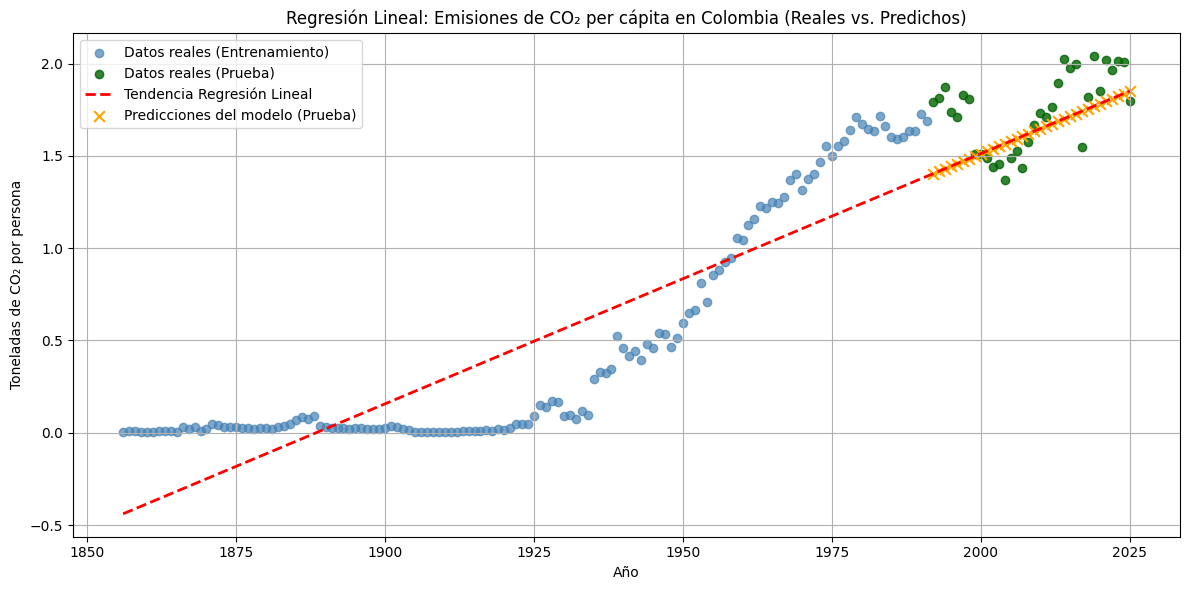

In [1]:
# ==============================================================================
# MODELO DE REGRESIÓN LINEAL: EMISIONES DE CO2 PER CÁPITA EN COLOMBIA
# ==============================================================================

# 1. Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 2. Cargar el dataset limpio y definir variables X e Y
df = pd.read_csv("emisiones_colombia_limpio.csv")
df = df.sort_values("Year").reset_index(drop=True)

X = df[["Year"]]               # Variable independiente (2D)
y = df["co2_per_capita"]       # Variable dependiente (1D)

# 3. Dividir los datos cronológicamente (80% entrenamiento, 20% prueba)
indice_corte = int(len(df) * 0.80)

X_train, y_train = X.iloc[:indice_corte], y.iloc[:indice_corte]
X_test, y_test = X.iloc[indice_corte:], y.iloc[indice_corte:]

print("=== RESUMEN DE DATOS ===")
print(f"Total de registros: {len(df)} ({int(df['Year'].min())} - {int(df['Year'].max())})")
print(f"Entrenamiento (80%): {len(X_train)} registros ({int(X_train['Year'].min())} - {int(X_train['Year'].max())})")
print(f"Prueba (20%):        {len(X_test)} registros ({int(X_test['Year'].min())} - {int(X_test['Year'].max())})")

# 4. Crear y entrenar el modelo de regresión lineal
modelo = LinearRegression()
modelo.fit(X_train, y_train)

pendiente = modelo.coef_[0]
intercepto = modelo.intercept_

print("\n=== ECUACIÓN DEL MODELO ===")
print(f"co2_per_capita = ({pendiente:.6f} * Year) + ({intercepto:.6f})")

# 5. Realizar predicciones sobre el conjunto de prueba
y_pred_test = modelo.predict(X_test)

# 6. Evaluar el modelo mediante métricas R², MAE y RMSE
r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("\n=== MÉTRICAS DE EVALUACIÓN (PRUEBA) ===")
print(f"R² (Coeficiente de determinación): {r2:.4f}")
print(f"MAE (Error Absoluto Medio):        {mae:.4f} toneladas/persona")
print(f"RMSE (Raíz del Error Cuadrático):  {rmse:.4f} toneladas/persona")

# 7. Gráfica comparativa: Valores reales vs. Valores predichos
plt.figure(figsize=(12, 6))
plt.scatter(X_train, y_train, color="steelblue", alpha=0.7, label="Datos reales (Entrenamiento)")
plt.scatter(X_test, y_test, color="darkgreen", alpha=0.8, label="Datos reales (Prueba)")
plt.plot(X, modelo.predict(X), color="red", linewidth=2, linestyle="--", label="Tendencia Regresión Lineal")
plt.scatter(X_test, y_pred_test, color="orange", marker="x", s=60, label="Predicciones del modelo (Prueba)")

plt.title("Regresión Lineal: Emisiones de CO₂ per cápita en Colombia (Reales vs. Predichos)")
plt.xlabel("Año")
plt.ylabel("Toneladas de CO₂ por persona")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()